In [113]:
import numpy as np
import matplotlib.pyplot as plt
import imageio

vertices start in a line
update position via monte carlo step
hooke's law
fixed points - boundary condtion
vertices can move in 2d
need to calculate angle between points
determine s by yourself, such that ~50% of the steps are accepted
try doing the move for all points simultaneously, but if it doesnt work, you can do it sequentially

1.2
0	35% -> Average bond length: 1.0002312066393415
100	31% -> Average bond length: 1.0020606930527678
200	36% -> Average bond length: 1.0033324308603315
300	43% -> Average bond length: 1.003409042926373
400	37% -> Average bond length: 1.0050894586063954
500	33% -> Average bond length: 1.0028271882414708
600	42% -> Average bond length: 1.0029006150809423
700	45% -> Average bond length: 1.0032814803094785
800	48% -> Average bond length: 1.004993454664289
900	35% -> Average bond length: 1.005246264538527
1000	44% -> Average bond length: 1.0065244836824292
1100	44% -> Average bond length: 1.009387294818741
1200	39% -> Average bond length: 1.011179702302496
1300	39% -> Average bond length: 1.013754408341847
1400	48% -> Average bond length: 1.0152682529055672
1500	41% -> Average bond length: 1.015859409907737
1600	27% -> Average bond length: 1.015799023548607
1700	42% -> Average bond length: 1.0180565151881076
1800	48% -> Average bond length: 1.0181652017668958
1900	43% -> Average bond len

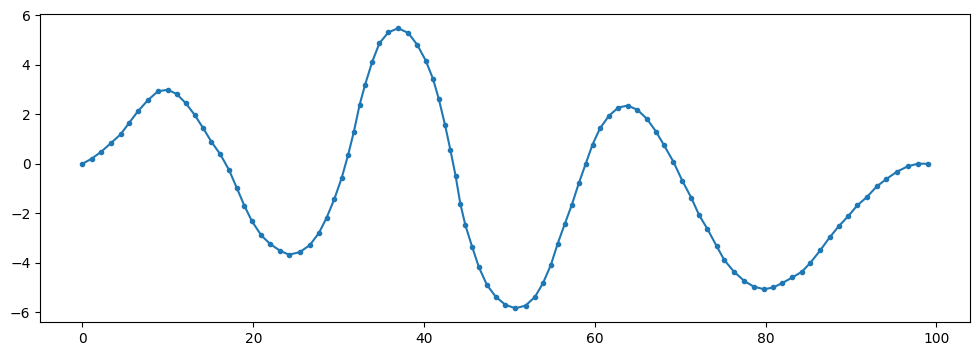

In [114]:
class System():
    def __init__(self, l_0, N: int, k, k_b, k_bT) -> None:
        self.l = l_0
        
        x = np.arange(N) * self.l
        y = np.zeros(N)
        self.pos = np.column_stack((x,y))
        # self.pos[1] = [1,self.l]

        self.k = k
        self.k_b = k_b
        self.k_bT = k_bT

    def plot(self):
        # plt.scatter(self.pos[:,0], self.pos[:,1])
        plt.figure(figsize=(12, 4))
        plt.plot(self.pos[:,0], self.pos[:,1], '.-')
        plt.show()

    def MonteCarloBatch(self, s, iteration=-1):
        N = len(self.pos)
        count = 0
        
        # randomize the order
        indices = np.arange(1, N-1)
        np.random.shuffle(indices)

        for i in indices:
            success = self.MonteCarloStep(i, s)
            if success:
                count += 1
                
        if iteration % 100 == 0:
            avg_bond = np.mean(np.linalg.norm(np.diff(self.pos, axis=0), axis=1))
            print(f"{iteration}\t{int((count/N) * 100)}% -> Average bond length: {avg_bond}")

    def MonteCarloStep(self, n: int, s):
        # make sure this isn't on of the bounds
        N = len(self.pos)
        assert n != 0 and n != (N-1)
        # calculate current energy (this is done for 2 springs and 3 vertices)
        past_pos = self.pos[n].copy()
        E_old = self.comp_ES(n) + self.comp_EB(n-1) + self.comp_EB(n) + self.comp_EB(n+1)
        # print(f"old energy: {E_old}")

        # update the position of a vertex by arandom interval
        noise = np.random.uniform(-s, s, size=(2,))
        self.pos[n] = self.pos[n] + noise

        E_new = self.comp_ES(n) + self.comp_EB(n-1) + self.comp_EB(n) + self.comp_EB(n+1)
        # print(f"old energy: {E_new}")

        # compute the energy differential
        delta = E_new - E_old

        # decide if the new position is accepted
        prob = np.random.uniform(0,0.9999)
        # if delta <= 0 or prob < min(1.0, np.exp(- delta / self.k_bT)):
        if prob < min(1.0, np.exp(- delta / self.k_bT)):
            # print(f"o")
            return True
        else:
            # print(f"-")
            self.pos[n] = past_pos
            return False

    def compute_cosine(self, n: int):
        N = len(self.pos)

        # current pos
        r = self.pos[n]

        # left neighbour
        if n == 0:
            r_left = np.array([r[0] - self.l, 0.0])
        else:
            r_left = self.pos[n-1]

        # right neighbour
        if n == N-1 or n == -1:
            r_right = np.array([r[0] + self.l, 0.0])
        else:
            r_right = self.pos[n+1]

        # vectors
        v1 = r_left - r
        v2 = r_right - r
        v3 = r_right - r_left

        # lengths
        a = np.linalg.norm(v1)
        b = np.linalg.norm(v2)
        c = np.linalg.norm(v3)

        # avoid division by 0
        if a == 0 or b == 0: return 0.0

        # law of cosines
        cos_theta = (a**2 + b**2 - c**2) / (2 * a * b)

        return cos_theta
    
    def comp_EB(self, n):
        # remember do this part for 3 vertices
        cos = self.compute_cosine(n)
        return self.k_b * (1 + cos)
    
    def comp_ES(self, n):
        # do this for only one vertex
        r = self.pos[n]

        # left neighbour
        r_left = self.pos[n-1]

        # right neighbour
        r_right = self.pos[n+1]

        # vectors
        v1 = r_left - r
        v2 = r_right - r

        # lengths
        a = np.linalg.norm(v1)
        b = np.linalg.norm(v2)

        return 0.5 * self.k * ((a - self.l)**2 + (b - self.l)**2)



# L_0 = 1
# n = 1e2
# K = 1e3
# K_B = 1e2
# K_BT = 1e-2

# system = System(l_0=L_0, N=int(n), k=K_B, k_b=K_B, k_bT=K_BT)
# system.plot()
# system.l = L_0*1.3
# print(system.l)
# for i in range(10000):
#     system.MonteCarloBatch(0.01, i)
# system.plot()

# def task1()
L_0 = 1
n = 1e2
K = 1e3
K_B = 1e2
K_BT = 5e-1

system = System(l_0=L_0, N=int(n), k=K_B, k_b=K_B, k_bT=K_BT)
system.l = L_0*1.2
print(system.l)
for i in range(30000):
    system.MonteCarloBatch(0.08, i)
system.plot()

1.1
0	36% -> Average bond length: 1.0002602768775508
100	45% -> Average bond length: 1.0016413911291142
200	54% -> Average bond length: 1.0025519107340477
300	39% -> Average bond length: 1.002455873136424
400	41% -> Average bond length: 1.002761620468908
500	30% -> Average bond length: 1.003009998090357
600	42% -> Average bond length: 1.002678951430742
700	32% -> Average bond length: 1.0027747398263196
800	41% -> Average bond length: 1.0040183348671108
900	42% -> Average bond length: 1.0026879596707026
1000	49% -> Average bond length: 1.0023615756234276
1100	36% -> Average bond length: 1.0036583925267835
1200	43% -> Average bond length: 1.0040557634427199
1300	46% -> Average bond length: 1.0038937800701744
1400	42% -> Average bond length: 1.0038356133090862
1500	46% -> Average bond length: 1.0039490214366984
1600	40% -> Average bond length: 1.0058976016689303
1700	42% -> Average bond length: 1.0062647799819775
1800	34% -> Average bond length: 1.0069552376557507
1900	39% -> Average bond

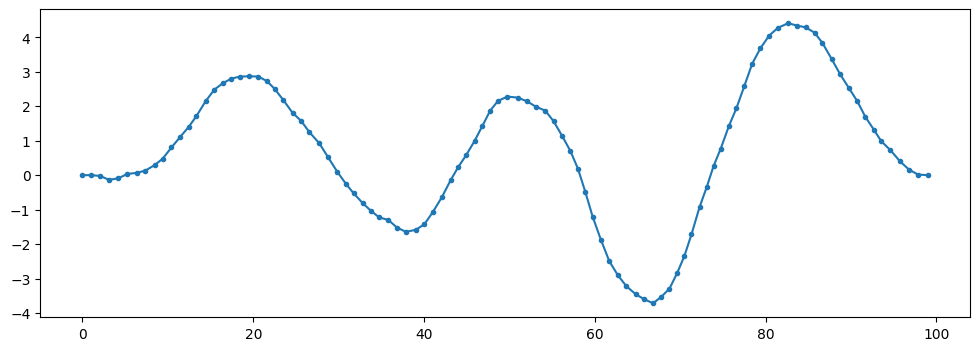

In [115]:
system = System(l_0=L_0, N=int(n), k=K_B, k_b=K_B, k_bT=K_BT)
system.l = L_0*1.1
print(system.l)
for i in range(30000):
    system.MonteCarloBatch(0.08, i)
system.plot()

1.5
0	91% -> Average bond length: 1.0000889041108163
100	82% -> Average bond length: 1.0011713425982596
200	85% -> Average bond length: 1.0016995042982721
300	83% -> Average bond length: 1.0027082876304594
400	82% -> Average bond length: 1.0030276426962945
500	82% -> Average bond length: 1.0025583641981177
600	86% -> Average bond length: 1.0035643021369713
700	80% -> Average bond length: 1.0039598414326345
800	86% -> Average bond length: 1.0043361454816284
900	85% -> Average bond length: 1.005423932238051
1000	82% -> Average bond length: 1.0078960008011475
1100	79% -> Average bond length: 1.0096555776468321
1200	83% -> Average bond length: 1.009793181068562
1300	80% -> Average bond length: 1.0109955014244743
1400	85% -> Average bond length: 1.0115787078981582
1500	82% -> Average bond length: 1.014331773622573
1600	84% -> Average bond length: 1.0140995196891158
1700	84% -> Average bond length: 1.0137335914528276
1800	84% -> Average bond length: 1.0136706932198063
1900	82% -> Average bon

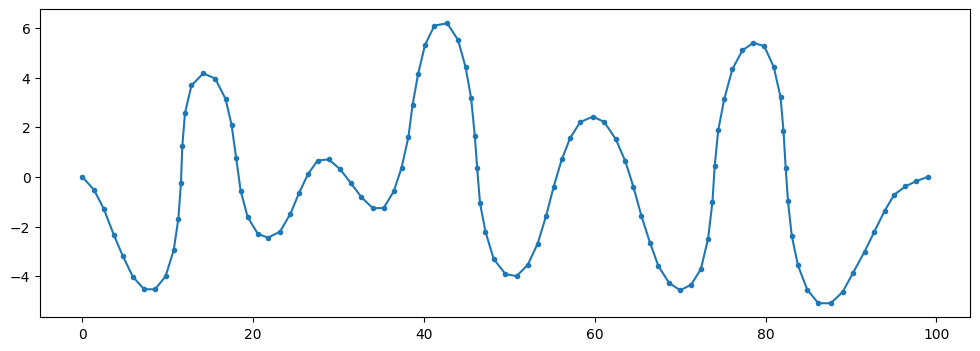

In [116]:
system = System(l_0=L_0, N=int(n), k=K_B, k_b=K_B, k_bT=K_BT)
system.l = L_0*1.5
print(system.l)
for i in range(30000):
    system.MonteCarloBatch(0.02, i)
system.plot()

1.8
0	56% -> Average bond length: 1.0002234116520454
100	62% -> Average bond length: 1.00401883183261
200	54% -> Average bond length: 1.0108583095123813
300	66% -> Average bond length: 1.03715954155784
400	62% -> Average bond length: 1.0829725814099311
500	66% -> Average bond length: 1.180440236896398
600	65% -> Average bond length: 1.3084239329584537
700	72% -> Average bond length: 1.4279496221840706
800	72% -> Average bond length: 1.5120424224513833
900	79% -> Average bond length: 1.5836453820675775
1000	72% -> Average bond length: 1.599589334973143
1100	64% -> Average bond length: 1.6203454847015961
1200	70% -> Average bond length: 1.613283113672675
1300	66% -> Average bond length: 1.6274058769501698
1400	68% -> Average bond length: 1.6286569697516557
1500	75% -> Average bond length: 1.6304014649391187
1600	66% -> Average bond length: 1.641658285876337
1700	73% -> Average bond length: 1.6480019033313653
1800	66% -> Average bond length: 1.6599163401929666
1900	75% -> Average bond len

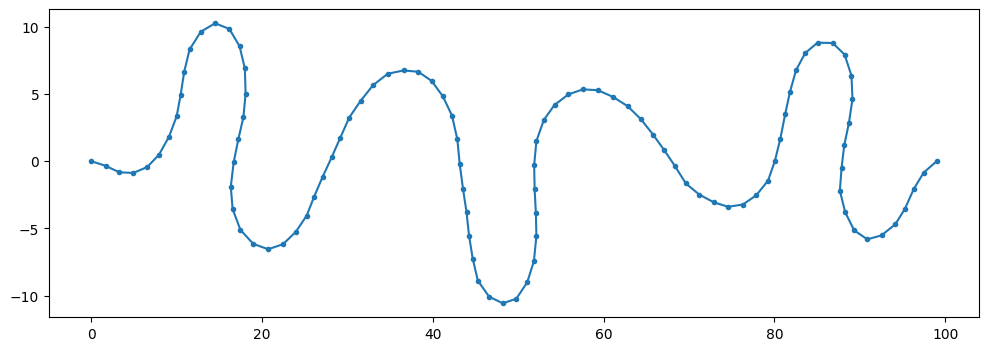

In [117]:
system = System(l_0=L_0, N=int(n), k=K_B, k_b=K_B, k_bT=K_BT)
system.l = L_0*1.8
print(system.l)
for i in range(20000):
    system.MonteCarloBatch(0.05, i)
system.plot()

2
0	31% -> Average bond length: 1.000461019757811
100	43% -> Average bond length: 1.0315056195970456
200	51% -> Average bond length: 1.3484309338909548
300	56% -> Average bond length: 1.743445139241031
400	46% -> Average bond length: 1.8307472782808347
500	48% -> Average bond length: 1.855803724992517
600	45% -> Average bond length: 1.840614449383587
700	54% -> Average bond length: 1.8374179456320503
800	56% -> Average bond length: 1.8408295592068886
900	55% -> Average bond length: 1.8264983828720596
1000	51% -> Average bond length: 1.8440015785750137
1100	61% -> Average bond length: 1.867726890792364
1200	61% -> Average bond length: 1.868493469395649
1300	56% -> Average bond length: 1.8961910125113934
1400	50% -> Average bond length: 1.8962051667272215
1500	52% -> Average bond length: 1.896191879192674
1600	60% -> Average bond length: 1.904265688125
1700	47% -> Average bond length: 1.9041870758320725
1800	56% -> Average bond length: 1.8962826031697453
1900	48% -> Average bond length: 

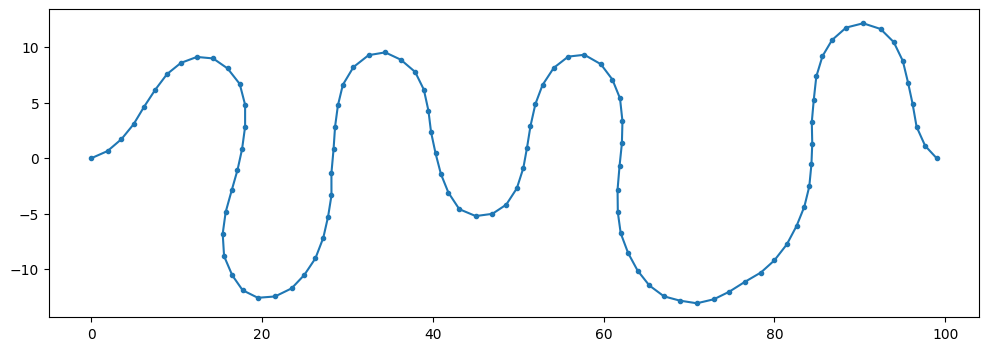

In [118]:
system = System(l_0=L_0, N=int(n), k=K_B, k_b=K_B, k_bT=K_BT)
system.l = L_0*2
print(system.l)
for i in range(20000):
    system.MonteCarloBatch(0.09, i)
system.plot()

4
0	30% -> Average bond length: 1.0040565519487223
100	40% -> Average bond length: 3.903446560009989
200	32% -> Average bond length: 3.946642033094929
300	35% -> Average bond length: 3.947442232743678
400	34% -> Average bond length: 3.9592624096047975
500	37% -> Average bond length: 3.965662333040547
600	40% -> Average bond length: 3.982726082413241
700	33% -> Average bond length: 3.9970565488165217
800	30% -> Average bond length: 3.9815173321408763
900	36% -> Average bond length: 3.979460366826106
1000	31% -> Average bond length: 3.9878178546651593
1100	19% -> Average bond length: 3.990527920848185
1200	31% -> Average bond length: 3.9997637808703375
1300	24% -> Average bond length: 4.008896790737213
1400	37% -> Average bond length: 4.00832309212914
1500	35% -> Average bond length: 4.011611903637455
1600	33% -> Average bond length: 3.99564834190656
1700	30% -> Average bond length: 4.009691310056653
1800	35% -> Average bond length: 3.9924615662940894
1900	31% -> Average bond length: 4.0

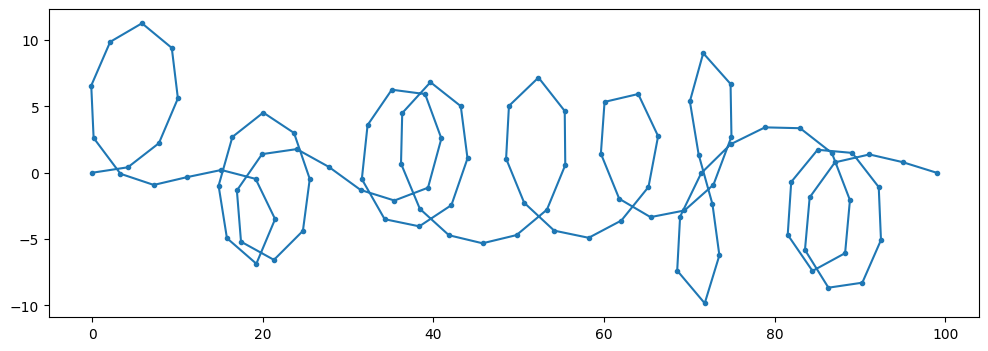

In [119]:
system = System(l_0=L_0, N=int(n), k=K_B, k_b=K_B, k_bT=K_BT)
system.l = L_0*4
print(system.l)
for i in range(2000):
    system.MonteCarloBatch(0.2, i)
system.plot()

In [ ]:
# task2
import numpy as np
import matplotlib.pyplot as plt
import imageio
from io import BytesIO

class System():
    def __init__(self, l_0, N: int, k, k_b, k_bT, p_growth: float) -> None:
        self.prob = p_growth
        self.l_0 = l_0
        self.l = np.full(N - 1, l_0, dtype=float)
        
        x = np.zeros(N)
        x[1:] = np.cumsum(self.l) 
        y = np.zeros(N)
        self.pos = np.column_stack((x,y))

        self.k = k
        self.k_b = k_b
        self.k_bT = k_bT
        
        # Array to store the frames for our GIF
        self.frames = []

    def plot(self):
        plt.figure(figsize=(12, 4))
        plt.plot(self.pos[:,0], self.pos[:,1], '.-')
        plt.title(f"Average Rest Length (l_0): {np.mean(self.l):.4f}")
        plt.show()

    # Added snapshot_interval parameter (defaults to 100)
    def MonteCarloBatch(self, s, delta_l0, iteration=-1, snapshot_interval=100):
        N = len(self.pos)
        
        # Spring Growth Step
        growth_attempts = np.random.random(N - 1)
        growth_mask = growth_attempts < self.prob
        self.l[growth_mask] += delta_l0

        count = 0
        indices = np.arange(1, N-1)
        np.random.shuffle(indices)

        for i in indices:
            success = self.MonteCarloStep(i, s)
            if success:
                count += 1
                
        # Utilize the internal print function to also capture the frame
        if iteration % snapshot_interval == 0:
            avg_bond = np.mean(np.linalg.norm(np.diff(self.pos, axis=0), axis=1))
            avg_l0 = np.mean(self.l)
            print(f"Iter {iteration}\tAccept: {int((count/N) * 100)}% -> Avg Bond: {avg_bond:.4f} (Avg l_0: {avg_l0:.4f})")
            
            # Capture the frame at this specific interval
            self.frames.append(self.capture_frame())

    def capture_frame(self):
        """Generates a snapshot of the current state and returns it as an image array."""
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(self.pos[:,0], self.pos[:,1], '.-')
        ax.set_title(f"Average Rest Length (l_0): {np.mean(self.l):.4f}")

        # =====================================================================
        # HIGHLIGHT: CONSTANT AXES
        # Set your fixed axis limits here to prevent the GIF from jittering!
        # Adjust these based on how much you expect the polymer to stretch.
        ax.set_ylim(-15, 15)  
        ax.set_xlim(-5, len(self.pos) * self.l_0) 
        # =====================================================================

        # Save plot to memory buffer
        buf = BytesIO()
        plt.savefig(buf, format='png', bbox_inches='tight')
        plt.close(fig) # Crucial: close the figure to prevent memory leaks
        buf.seek(0)
        
        return imageio.v2.imread(buf)
    
    def save_gif(self, filename="polymer_simulation.gif", fps=10):
        """Compiles captured frames into a looping GIF."""
        if not self.frames:
            print("No frames captured! Try running the simulation first.")
            return
            
        print(f"Saving GIF with {len(self.frames)} frames...")
        # duration is in milliseconds per frame (e.g., 1000 / 10 fps = 100ms)
        duration_ms = 1000 / fps 
        imageio.mimsave(filename, self.frames, duration=duration_ms, loop=0)
        print(f"Saved to {filename}")

    def MonteCarloStep(self, n: int, s):
        N = len(self.pos)
        assert n != 0 and n != (N-1)
        
        past_pos = self.pos[n].copy()
        E_old = self.comp_ES(n) + self.comp_EB(n-1) + self.comp_EB(n) + self.comp_EB(n+1)

        noise = np.random.uniform(-s, s, size=(2,))
        self.pos[n] = self.pos[n] + noise

        E_new = self.comp_ES(n) + self.comp_EB(n-1) + self.comp_EB(n) + self.comp_EB(n+1)
        delta = E_new - E_old

        prob = np.random.random()
        if prob < min(1.0, np.exp(- delta / self.k_bT)):
            return True
        else:
            self.pos[n] = past_pos
            return False

    def compute_cosine(self, n: int):
        N = len(self.pos)
        r = self.pos[n]
        if n == 0: r_left = np.array([r[0] - self.l[0], 0.0])
        else: r_left = self.pos[n-1]
        if n == N-1 or n == -1: r_right = np.array([r[0] + self.l[-1], 0.0])
        else: r_right = self.pos[n+1]

        v1 = r_left - r
        v2 = r_right - r
        a = np.linalg.norm(v1)
        b = np.linalg.norm(v2)
        if a == 0 or b == 0: return 0.0
        return np.clip(np.dot(v1, v2) / (a * b), -1.0, 1.0)
    
    def comp_EB(self, n):
        cos = self.compute_cosine(n)
        return self.k_b * (1 + cos)
    
    def comp_ES(self, n):
        r = self.pos[n]
        r_left = self.pos[n-1]
        r_right = self.pos[n+1]
        v1 = r_left - r
        v2 = r_right - r
        a = np.linalg.norm(v1)
        b = np.linalg.norm(v2)
        return 0.5 * self.k * ((a - self.l[n-1])**2 + (b - self.l[n])**2)


L_0 = 1
n_vertices = 1e2
K = 1e3
K_B = 1e2
K_BT = 5e-1

P_GROWTH = 0.01
DELTA_L0 = 0.01    

system = System(l_0=L_0, N=int(n_vertices), k=K_B, k_b=K_B, k_bT=K_BT, p_growth=P_GROWTH)

for i in range(20000): 
    system.MonteCarloBatch(s=0.08, delta_l0=DELTA_L0, iteration=i, snapshot_interval=100)

# Compile
system.save_gif("polymer_growth.gif", fps=10)

Iter 0	Accept: 36% -> Avg Bond: 1.0003 (Avg l_0: 1.0000)
Iter 100	Accept: 37% -> Avg Bond: 1.0016 (Avg l_0: 1.0105)
Iter 200	Accept: 41% -> Avg Bond: 1.0020 (Avg l_0: 1.0207)
Iter 300	Accept: 48% -> Avg Bond: 1.0025 (Avg l_0: 1.0332)
Iter 400	Accept: 38% -> Avg Bond: 1.0023 (Avg l_0: 1.0438)
Iter 500	Accept: 40% -> Avg Bond: 1.0023 (Avg l_0: 1.0536)
Iter 600	Accept: 40% -> Avg Bond: 1.0027 (Avg l_0: 1.0633)
Iter 700	Accept: 42% -> Avg Bond: 1.0034 (Avg l_0: 1.0742)
Iter 800	Accept: 37% -> Avg Bond: 1.0042 (Avg l_0: 1.0844)
Iter 900	Accept: 33% -> Avg Bond: 1.0041 (Avg l_0: 1.0935)
Iter 1000	Accept: 45% -> Avg Bond: 1.0037 (Avg l_0: 1.1030)
Iter 1100	Accept: 38% -> Avg Bond: 1.0042 (Avg l_0: 1.1129)
Iter 1200	Accept: 37% -> Avg Bond: 1.0054 (Avg l_0: 1.1240)
Iter 1300	Accept: 48% -> Avg Bond: 1.0051 (Avg l_0: 1.1347)
Iter 1400	Accept: 42% -> Avg Bond: 1.0058 (Avg l_0: 1.1446)
Iter 1500	Accept: 36% -> Avg Bond: 1.0056 (Avg l_0: 1.1551)
Iter 1600	Accept: 44% -> Avg Bond: 1.0080 (Avg l_0: 

In [5]:
L_0 = 1
n_vertices = 1e2
K = 1e3
K_B = 1e2
K_BT = 5e-1

P_GROWTH = 0.1
DELTA_L0 = 0.01    

system = System(l_0=L_0, N=int(n_vertices), k=K_B, k_b=K_B, k_bT=K_BT, p_growth=P_GROWTH)

for i in range(5000): 
    system.MonteCarloBatch(s=0.08, delta_l0=DELTA_L0, iteration=i, snapshot_interval=100)

# Compile
system.save_gif("polymer_growth2.gif", fps=10)

Iter 0	Accept: 22% -> Avg Bond: 1.0001 (Avg l_0: 1.0006)
Iter 100	Accept: 45% -> Avg Bond: 1.0023 (Avg l_0: 1.1021)
Iter 200	Accept: 35% -> Avg Bond: 1.0021 (Avg l_0: 1.2078)
Iter 300	Accept: 47% -> Avg Bond: 1.0039 (Avg l_0: 1.3073)
Iter 400	Accept: 39% -> Avg Bond: 1.0044 (Avg l_0: 1.4090)
Iter 500	Accept: 45% -> Avg Bond: 1.0080 (Avg l_0: 1.5108)
Iter 600	Accept: 50% -> Avg Bond: 1.0219 (Avg l_0: 1.6078)
Iter 700	Accept: 48% -> Avg Bond: 1.0853 (Avg l_0: 1.7102)
Iter 800	Accept: 53% -> Avg Bond: 1.2712 (Avg l_0: 1.8142)
Iter 900	Accept: 54% -> Avg Bond: 1.5972 (Avg l_0: 1.9186)
Iter 1000	Accept: 59% -> Avg Bond: 1.8280 (Avg l_0: 2.0191)
Iter 1100	Accept: 67% -> Avg Bond: 1.9872 (Avg l_0: 2.1196)
Iter 1200	Accept: 59% -> Avg Bond: 2.0959 (Avg l_0: 2.2221)
Iter 1300	Accept: 66% -> Avg Bond: 2.2054 (Avg l_0: 2.3234)
Iter 1400	Accept: 61% -> Avg Bond: 2.3361 (Avg l_0: 2.4242)
Iter 1500	Accept: 57% -> Avg Bond: 2.4299 (Avg l_0: 2.5221)
Iter 1600	Accept: 56% -> Avg Bond: 2.5286 (Avg l_0: 

In [6]:
L_0 = 1
n_vertices = 1e2
K = 1e3
K_B = 1e2
K_BT = 5e-1

P_GROWTH = 0.001
DELTA_L0 = 0.01    

system = System(l_0=L_0, N=int(n_vertices), k=K_B, k_b=K_B, k_bT=K_BT, p_growth=P_GROWTH)

for i in range(30000): 
    system.MonteCarloBatch(s=0.08, delta_l0=DELTA_L0, iteration=i, snapshot_interval=100)

# Compile
system.save_gif("polymer_growth3.gif", fps=10)

Iter 0	Accept: 46% -> Avg Bond: 1.0003 (Avg l_0: 1.0000)
Iter 100	Accept: 46% -> Avg Bond: 1.0024 (Avg l_0: 1.0007)
Iter 200	Accept: 44% -> Avg Bond: 1.0022 (Avg l_0: 1.0014)
Iter 300	Accept: 41% -> Avg Bond: 1.0028 (Avg l_0: 1.0025)
Iter 400	Accept: 41% -> Avg Bond: 1.0034 (Avg l_0: 1.0036)
Iter 500	Accept: 37% -> Avg Bond: 1.0039 (Avg l_0: 1.0048)
Iter 600	Accept: 45% -> Avg Bond: 1.0028 (Avg l_0: 1.0063)
Iter 700	Accept: 46% -> Avg Bond: 1.0033 (Avg l_0: 1.0072)
Iter 800	Accept: 36% -> Avg Bond: 1.0033 (Avg l_0: 1.0077)
Iter 900	Accept: 47% -> Avg Bond: 1.0033 (Avg l_0: 1.0086)
Iter 1000	Accept: 38% -> Avg Bond: 1.0041 (Avg l_0: 1.0097)
Iter 1100	Accept: 53% -> Avg Bond: 1.0046 (Avg l_0: 1.0114)
Iter 1200	Accept: 37% -> Avg Bond: 1.0041 (Avg l_0: 1.0133)
Iter 1300	Accept: 43% -> Avg Bond: 1.0043 (Avg l_0: 1.0142)
Iter 1400	Accept: 34% -> Avg Bond: 1.0048 (Avg l_0: 1.0156)
Iter 1500	Accept: 42% -> Avg Bond: 1.0055 (Avg l_0: 1.0164)
Iter 1600	Accept: 42% -> Avg Bond: 1.0061 (Avg l_0: 

In [120]:
if False:
    class System():
        def __init__(self,l_0, N, k, k_b, k_bT):
            # there will be 1 fewer connections than vertices
            self.l = np.full(int(N-1), l_0)
            # arange the points in a line 
            x = np.arange(N) * l_0
            y = np.zeros(int(N))
            self.pos = np.column_stack((x,y))

            # # for testing
            # no = 3
            # self.pos[no] = self.pos[no] + [0,1]
            self.k = k
            self.k_b = k_b
            self.k_bT = k_bT
            # self.plot()


        def plot(self):
            # plt.scatter(self.pos[:,0], self.pos[:,1])
            plt.figure(figsize=(12, 4))
            plt.plot(self.pos[:,0], self.pos[:,1], '.-')
            plt.show

        def calculate_spring_energy(self, verbose=False):
            # spring vectors (i -> i+1)
            diff = self.pos[1:] - self.pos[:-1]

            # spring lengths
            dist = np.linalg.norm(diff, axis=1)

            # extension
            dl = dist - self.l

            # energy per spring
            E_springs = 0.5 * self.k * dl**2

            # per-vertex energy (N vertices)
            E_vertices = np.zeros(self.pos.shape[0])

            # each spring contributes half to each of its two vertices
            E_vertices[:-1] += 0.5 * E_springs
            E_vertices[1:]  += 0.5 * E_springs

            if verbose:
                print("Spring lengths:", dist)
                print("Spring energies:", E_springs)
                print("Vertex energies:", E_vertices)

            return E_vertices

        def calculate_bending_energy(self, verbose=False):
            # neighbors
            prev = np.roll(self.pos, 1, axis=0)
            next = np.roll(self.pos, -1, axis=0)

            # vectors (for distances a and b)
            v1 = self.pos - prev
            v2 = next - self.pos

            # side lengths
            a = np.linalg.norm(v1, axis=1)
            b = np.linalg.norm(v2, axis=1)

            # vector from prev to next (for c)
            v3 = next - prev
            c = np.linalg.norm(v3, axis=1)

            # avoid division by zero
            eps = 1e-12
            a_safe = np.maximum(a, eps)
            b_safe = np.maximum(b, eps)

            # law of cosines
            cos_theta = (a_safe**2 + b_safe**2 - c**2) / (2 * a_safe * b_safe)

            # numerical stability
            cos_theta = np.clip(cos_theta, -1.0, 1.0)

            # bending energy
            E_b = self.k_b * (1 + cos_theta)

            # boundary conditions (no angle at endpoints)
            E_b[0] = 0.0
            E_b[-1] = 0.0

            if verbose:
                print("a:", a)
                print("b:", b)
                print("c:", c)
                print("cos(theta):", cos_theta)
                print("Bending energy:", E_b)

            return E_b
            
        def calculate_energy(self, verbose=False):
            spring_energy = self.calculate_spring_energy()
            bending_energy = self.calculate_bending_energy()
            if verbose:
                print(f"spring energy:\n{spring_energy}")
                print(f"bending energy:\n{bending_energy}")
                print(f"total energy:\n{(bending_energy+spring_energy)}")
            return spring_energy + bending_energy
        
        def disturb_positions(self, s):
            noise = np.random.uniform(-s, s, size=self.pos.shape)

            # apply only to interior points
            self.pos[1:-1] += noise[1:-1]

        def monte_carlo_step(self, s, verbose=False):
            old_pos = self.pos.copy()
            old_energy = np.sum(self.calculate_energy())

            noise = np.random.uniform(-s, s, size=self.pos.shape)
            self.pos[1:-1] += noise[1:-1]

            new_energy = np.sum(self.calculate_energy())
            delta_E = new_energy - old_energy

            # if delta_E <= 0:
            #     accept = True
            # else:
            prob = np.exp(-delta_E / self.k_bT)
            accept = np.random.rand() < prob

            if not accept:
                self.pos = old_pos

            if verbose:
                print(f"ΔE = {delta_E}, accepted = {accept}")

            return accept

        def modify_l(self, eps):
            self.l = self.l * (1 + eps)

        def modify_l_task2(self, eps):
            self.l = self.l + eps

        def monte_carlo_step_1(self, s, verbose=False):
                N = self.pos.shape[0]
                if N <= 2:
                    return False # Cannot perturb interior of a 2-particle system
                    
                # 1. Randomly select ONE interior vertex
                i = np.random.randint(1, N - 1)
                
                # Helper function to calculate energy specifically tied to vertex 'index'
                def calc_local_energy(index):
                    E_local = 0.0
                    
                    # --- 2 Springs ---
                    # Spring left (index-1 to index)
                    dist_left = np.linalg.norm(self.pos[index] - self.pos[index - 1])
                    E_local += 0.5 * self.k * (dist_left - self.l[index - 1])**2
                    
                    # Spring right (index to index+1)
                    dist_right = np.linalg.norm(self.pos[index + 1] - self.pos[index])
                    E_local += 0.5 * self.k * (dist_right - self.l[index])**2
                    
                    # --- 3 Bending Angles ---
                    # Vertices defining angles can be centered at index-1, index, and index+1 
                    # (Loop bounded by the array limits to avoid endpoints where E_b = 0)
                    for j in range(max(1, index - 1), min(N - 1, index + 2)):
                        a = np.linalg.norm(self.pos[j] - self.pos[j - 1])
                        b = np.linalg.norm(self.pos[j + 1] - self.pos[j])
                        c = np.linalg.norm(self.pos[j + 1] - self.pos[j - 1])
                        
                        # Prevent division by zero
                        a = max(a, 1e-12)
                        b = max(b, 1e-12)
                        
                        cos_theta = (a**2 + b**2 - c**2) / (2 * a * b)
                        cos_theta = np.clip(cos_theta, -1.0, 1.0)
                        
                        E_local += self.k_b * (1 + cos_theta)
                        
                    return E_local

                # 2. Calculate local energy BEFORE the move
                E_old = calc_local_energy(i)
                
                # 3. Save original position and apply random displacement to vertex i
                old_pos_i = self.pos[i].copy()
                self.pos[i] += np.random.uniform(-s, s, size=2)
                
                # 4. Calculate local energy AFTER the move
                E_new = calc_local_energy(i)
                
                # 5. Energy Delta
                delta_E = E_new - E_old
                
                # 6. Evaluate acceptance probability
                # IF delta_E <= 0, prob > 1, so np.random.rand() < prob is always True.
                prob = np.exp(-delta_E / self.k_bT)
                accept = np.random.rand() < prob
                
                # 7. Revert position if rejected
                if not accept:
                    self.pos[i] = old_pos_i
                    
                if verbose:
                    print(f"Vertex {i} moved. ΔE = {delta_E:.4e}, accepted = {accept}")
                    
                return accept

    def run_simulation(l_0, N, k, k_b, k_bT, steps, s, eps):
        system = System(l_0, N, k, k_b, k_bT)
        system.modify_l(eps)

        acceptance_buffer = []

        for i in range(steps):
            accepted = system.monte_carlo_step_1(s=s, verbose=False)

            acceptance_buffer.append(accepted)

            # keep only last 100 steps
            if len(acceptance_buffer) > 100:
                acceptance_buffer.pop(0)

            # print every 100 steps
            if (i + 1) % 1000 == 0:
                avg_acceptance = np.mean(acceptance_buffer)
                print(f"Step {i+1}: acceptance rate (last 100) = {avg_acceptance:.3f}")

        system.plot()

    def run_simulation_task2(l_0, N, k, k_b, k_bT, steps, s, eps):
        system = System(l_0, N, k, k_b, k_bT)

        acceptance_buffer = []

        for i in range(steps):
            accepted = system.monte_carlo_step_1(s=s, verbose=False)

            acceptance_buffer.append(accepted)

            # keep only last 100 steps
            if len(acceptance_buffer) > 100:
                acceptance_buffer.pop(0)

            # print every 100 steps
            if (i + 1) % 1000 == 0:
                system.modify_l_task2(eps)
                print(np.average(system.l))
                system.plot()
                avg_acceptance = np.mean(acceptance_buffer)
                print(f"Step {i+1}: acceptance rate (last 100) = {avg_acceptance:.3f}")

        system.plot()

    run_simulation(1.0, 3*1e2, 1e3, 1e2, 1, 10000, 0.05, 0.01)
    # run_simulation_task2(1.0, 100, 1e3, 1e2, 1e-1, 10000, 0.001, 0.1)